# 🩺 Holistic Health & Lifestyle Score: Hypothesis Testing and Machine Learning Model Selection
### Predicting Health Status (classification) and Overall Health Score (regression)
**Author:** Hema | **Role in project:** Machine learning models, conclusion, best-model selection

---
## 🎯 Objectives
- Build and compare ML models (baseline vs Logistic/Linear Regression vs Random Forest).
- Pick the best model using cross-validation, not guesswork.
- Export results for the team dashboard.

## 📊 About the data
- Synthetic dataset: each row is a person, with lifestyle habits and a calculated health score.
- **Features:** Physical_Activity, Nutrition_Score, Stress_Level, Mindfulness, Sleep_Hours, Hydration, BMI, Alcohol, Smoking
- **Targets:** `Health_Status` (Poor / Average / Good) for classification, and `Overall_Health_Score` (number) for regression
- ⚠️ Both targets are excluded from the features to avoid **data leakage**.

## 1️⃣ Setup: Libraries, Folders and Data Loading
**What I am going to do**
- Import tools, create output folders, and load the cleaned dataset.

In [1]:
# Data handling and maths
import numpy as np
import pandas as pd

# Charts
import matplotlib.pyplot as plt
import seaborn as sns

# Statistics
from scipy import stats

# Machine learning tools
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import (accuracy_score, f1_score, confusion_matrix,
                             classification_report, r2_score, mean_squared_error,
                             mean_absolute_error)

from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

# Make all charts look clean and colourful
sns.set_theme(style="whitegrid", palette="Set2")

# Create folders for saved charts and result files
visuals_dir = Path("../visuals")
outputs_dir = Path("../outputs")
for folder in (visuals_dir, outputs_dir):
    folder.mkdir(parents=True, exist_ok=True)

# Load the cleaned dataset
df = pd.read_csv("../cleaned_datasets/holistic_health_lifestyle_cleaned.csv")

**What it did**
- Loaded the libraries and the cleaned data, and made sure the `visuals` and `outputs` folders exist.

## 2️⃣ Quick Data Check
**What I am going to do**
- Check size, missing values, and the exact class names in `Health_Status`.
- This avoids errors later, such as a confusion matrix full of zeros caused by a wrong label name.

In [2]:
print("Rows, columns:", df.shape)
print("Missing values:", df.isna().sum().sum())
print("\nHealth_Status counts:")
print(df["Health_Status"].value_counts())
df.head()

Rows, columns: (10000, 11)
Missing values: 0

Health_Status counts:
Health_Status
Good       6759
Average    2823
Poor        418
Name: count, dtype: int64


,Physical_Activity,Nutrition_Score,Stress_Level,Mindfulness,Sleep_Hours,Hydration,BMI,Alcohol,Smoking,Overall_Health_Score,Health_Status
0,54.934283,5.643011,5.696572,0.000000,6.292214,2.578565,24.275932,4.280610,8.984006,36.950187,Poor
1,42.234714,6.389001,5.566647,4.450144,8.519054,2.448713,25.970141,7.461846,3.223304,55.167774,Average
2,57.953771,5.805238,3.126960,9.129716,6.702720,3.261433,25.193857,0.000000,4.600482,78.304426,Good
3,75.460597,7.220836,6.159168,16.496689,7.135854,3.726265,19.527300,9.958423,3.947706,94.018274,Good
4,40.316933,9.394357,2.019835,25.241623,8.076086,3.049478,23.348229,4.320347,8.084322,100.000000,Good


**What it did**
- Showed the dataset size, confirmed missing values, and listed the class names and how common each class is.
- The most common class sets the **baseline accuracy** that our models must beat.

## 3️⃣ Hypothesis Q1 and Q2: Physical Activity and Nutrition vs Health Score
**What I am going to do**
- Write one reusable function that calculates the Pearson correlation (r), its p-value, and draws a scatter plot with a trendline.

**Learn this (how to read r):**
- 0 to 0.3 = weak, 0.3 to 0.5 = moderate, 0.5 and above = strong.
- A small p-value (< 0.05) means the relationship is unlikely to be chance.

In [3]:
corr_results = {}  # store each r value so we can compare later

def corr_plot(x_col, x_label, color, file_name):
    """Correlation + p-value + scatter plot with trendline against Overall_Health_Score."""
    r, p = stats.pearsonr(df[x_col], df["Overall_Health_Score"])
    corr_results[x_col] = r
    print(f"{x_col}: r = {r:.4f}, p-value = {p:.2e}")

    plt.figure(figsize=(8, 5))
    sns.regplot(data=df, x=x_col, y="Overall_Health_Score",
                scatter_kws={"alpha": 0.3, "color": color},
                line_kws={"color": "black"})
    plt.title(f"{x_label} vs Overall Health Score", fontweight="bold")
    plt.xlabel(x_label)
    plt.ylabel("Overall Health Score")
    plt.tight_layout()
    plt.savefig(visuals_dir / file_name, dpi=300)
    plt.show()

# Q1: Physical activity
corr_plot("Physical_Activity", "Physical Activity (Minutes/Week)", "tomato", "q1_physical_activity_vs_health.png")

# Q2: Nutrition
corr_plot("Nutrition_Score", "Nutrition Score (0-10)", "seagreen", "q2_nutrition_vs_health.png")

Physical_Activity: r = 0.1460, p-value = 8.88e-49


<Figure size 800x500 with 1 Axes>

Nutrition_Score: r = 0.3857, p-value = 0.00e+00


<Figure size 800x500 with 1 Axes>

**What it did**
- Printed r and p-value for each variable and drew a scatter plot with a trendline.
- **Q1:** Physical activity has a **weak** positive link with health score (fill in r from the output above).
- **Q2:** Nutrition has a **moderate** positive link (fill in r from the output above).
- Both are statistically significant if p < 0.05.

## 4️⃣ Hypothesis Q3: Do Smokers Have Different Health Scores?
**What I am going to do**
- Split people into Smoker (Smoking > 0) and Non-Smoker.
- Compare average health scores and run a **Welch t-test**.

**Learn this:**
- A t-test checks whether two group averages are really different or just random.
- p < 0.05 means a significant difference.

Smoking_Group
Non-Smoker    84.84
Smoker        76.58
Name: Overall_Health_Score, dtype: float64

T-statistic = -19.1716, p-value = 4.05e-78


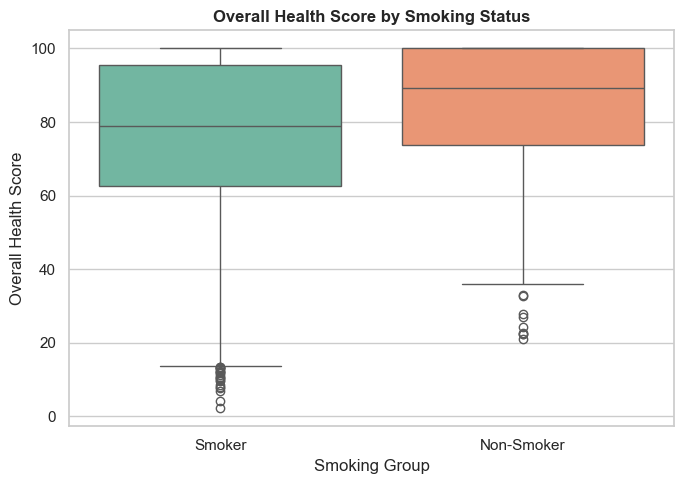

In [4]:
df["Smoking_Group"] = np.where(df["Smoking"] > 0, "Smoker", "Non-Smoker")

print(df.groupby("Smoking_Group")["Overall_Health_Score"].mean().round(2))

smokers = df.loc[df["Smoking_Group"] == "Smoker", "Overall_Health_Score"]
non_smokers = df.loc[df["Smoking_Group"] == "Non-Smoker", "Overall_Health_Score"]
t_stat, p_val = stats.ttest_ind(smokers, non_smokers, equal_var=False)
print(f"\nT-statistic = {t_stat:.4f}, p-value = {p_val:.2e}")

plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="Smoking_Group", y="Overall_Health_Score",
            hue="Smoking_Group", palette="Set2", legend=False)
plt.title("Overall Health Score by Smoking Status", fontweight="bold")
plt.xlabel("Smoking Group")
plt.ylabel("Overall Health Score")
plt.tight_layout()
plt.savefig(visuals_dir / "q3_smoking_vs_health_boxplot.png", dpi=300)
plt.show()

**What it did**
- Compared the two group means and tested the difference.
- If p < 0.05, non-smokers and smokers differ significantly, and the group with the higher mean has better health scores.

## 5️⃣ Hypothesis Q5: Is Mindfulness Linked More Strongly to Health Than Physical Activity?
**What I am going to do**
- Calculate r for Mindfulness and compare it directly with Physical Activity from Q1.
- The stronger relationship is the one with the larger **absolute** r value.

Mindfulness: r = 0.7159, p-value = 0.00e+00


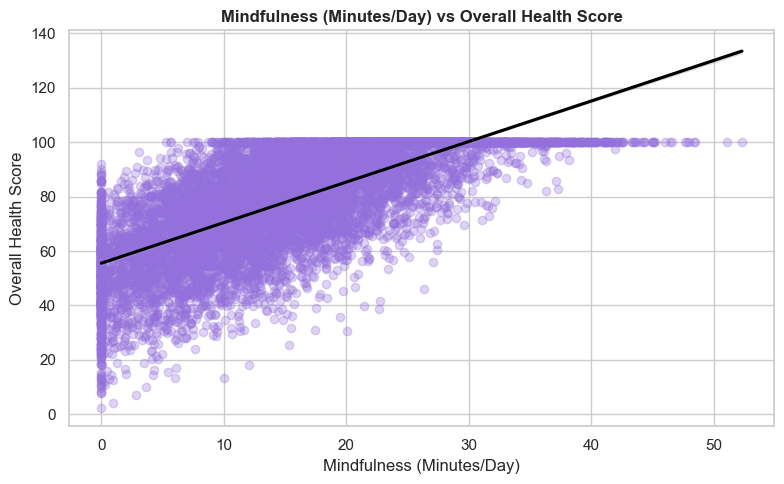


Mindfulness r = 0.7159 | Physical Activity r = 0.1460
Conclusion: Mindfulness has the stronger association with Overall Health Score.


In [5]:
corr_plot("Mindfulness", "Mindfulness (Minutes/Day)", "mediumpurple", "q5_mindfulness_vs_health.png")

r_mind = corr_results["Mindfulness"]
r_pa = corr_results["Physical_Activity"]
stronger = "Mindfulness" if abs(r_mind) > abs(r_pa) else "Physical activity"
print(f"\nMindfulness r = {r_mind:.4f} | Physical Activity r = {r_pa:.4f}")
print(f"Conclusion: {stronger} has the stronger association with Overall Health Score.")

**What it did**
- Printed both correlations and automatically stated which one is stronger.
- Remember: a stronger correlation does **not** mean it causes better health.

# Classification

## 6️⃣ Hypothesis Q4: Predicting Health Status (Classification)
**What I am going to do**
- Predict Poor / Average / Good from the 9 lifestyle features.
- Compare 3 models: **Baseline** (always guess the most common class), **Logistic Regression** (simple, linear), and **Random Forest** (many decision trees, handles complex patterns).
- Use an 80/20 stratified split and 5-fold cross-validation.

**Learn this:**
- **Train/test split:** train on 80%, test on unseen 20%.
- **Stratified:** keeps the class proportions the same in both parts.
- **Pipeline:** scaling happens inside each fold, so no information leaks from test to train.
- **Macro F1:** averages the F1 of every class equally, so it is fairer than accuracy when classes are unbalanced.
- **Cross-validation:** trains and tests 5 times on different slices, so the score is more trustworthy than one split.

In [6]:
feature_cols = ["Physical_Activity", "Nutrition_Score", "Stress_Level", "Mindfulness",
                "Sleep_Hours", "Hydration", "BMI", "Alcohol", "Smoking"]
X = df[feature_cols]
y_clf = df["Health_Status"]

# Safety check: class names must match the order we use for charts
labels = ["Poor", "Average", "Good"]
assert set(labels) == set(y_clf.unique()), f"Rename labels to match: {y_clf.unique()}"

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X, y_clf, test_size=0.2, random_state=42, stratify=y_clf)

clf_models = {
    "Baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": Pipeline([("scale", StandardScaler()),
                                     ("model", LogisticRegression(max_iter=1000))]),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rows = []
for name, model in clf_models.items():
    cv = cross_validate(model, X_train_c, y_train_c, cv=skf, scoring=["accuracy", "f1_macro"])
    model.fit(X_train_c, y_train_c)
    pred = model.predict(X_test_c)
    rows.append({
        "Model": name,
        "CV_Accuracy": cv["test_accuracy"].mean(),
        "CV_F1_Macro": cv["test_f1_macro"].mean(),
        "CV_F1_Std": cv["test_f1_macro"].std(),
        "Test_Accuracy": accuracy_score(y_test_c, pred),
        "Test_F1_Macro": f1_score(y_test_c, pred, average="macro"),
    })

clf_results = pd.DataFrame(rows).round(4)
clf_results.to_csv(outputs_dir / "classification_model_comparison.csv", index=False)
clf_results

,Model,CV_Accuracy,CV_F1_Macro,CV_F1_Std,Test_Accuracy,Test_F1_Macro
0,Baseline,0.6759,0.2689,0.0001,0.6760,0.2689
1,Logistic Regression,0.9920,0.9805,0.0092,0.9955,0.9886
2,Random Forest,0.9049,0.7803,0.0079,0.9130,0.7968


**What it did**
- Trained 3 models, scored each with cross-validation and on the unseen test set, and saved the table.
- A real model must beat the **Baseline**, otherwise it has learned nothing.
- A small `CV_F1_Std` means the model is stable.

### Choosing the Best Classifier
**What I am going to do**
- Pick the best non-baseline model by highest cross-validated Macro F1, then inspect it with a confusion matrix and classification report.

🏆 Best classifier: Logistic Regression

              precision    recall  f1-score   support

        Poor       1.00      0.95      0.98        84
     Average       0.99      0.99      0.99       564
        Good       1.00      1.00      1.00      1352

    accuracy                           1.00      2000
   macro avg       1.00      0.98      0.99      2000
weighted avg       1.00      1.00      1.00      2000



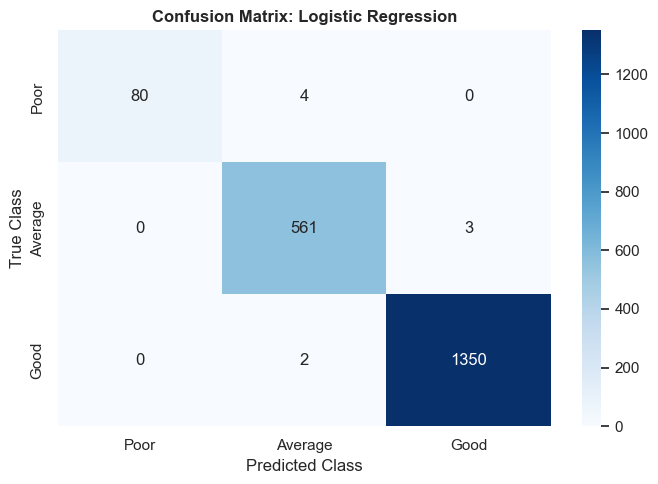

In [7]:
best_clf_name = (clf_results[clf_results["Model"] != "Baseline"]
                 .sort_values("CV_F1_Macro", ascending=False).iloc[0]["Model"])
best_clf = clf_models[best_clf_name]
best_pred = best_clf.predict(X_test_c)
print(f"🏆 Best classifier: {best_clf_name}\n")
print(classification_report(y_test_c, best_pred, labels=labels))

cm = confusion_matrix(y_test_c, best_pred, labels=labels)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)
plt.title(f"Confusion Matrix: {best_clf_name}", fontweight="bold")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.tight_layout()
plt.savefig(visuals_dir / "classification_confusion_matrix.png", dpi=300)
plt.show()

**What it did**
- Named the best classifier and printed precision, recall and F1 for each class.
- The confusion matrix shows where mistakes happen: the diagonal is correct, off-diagonal is wrong.
- **Only describe mistakes that the matrix actually shows.**

**Learn this:**
- **Precision:** of the people predicted as a class, how many really were.
- **Recall:** of the people who really were that class, how many we found.
- **F1:** the balance of the two.

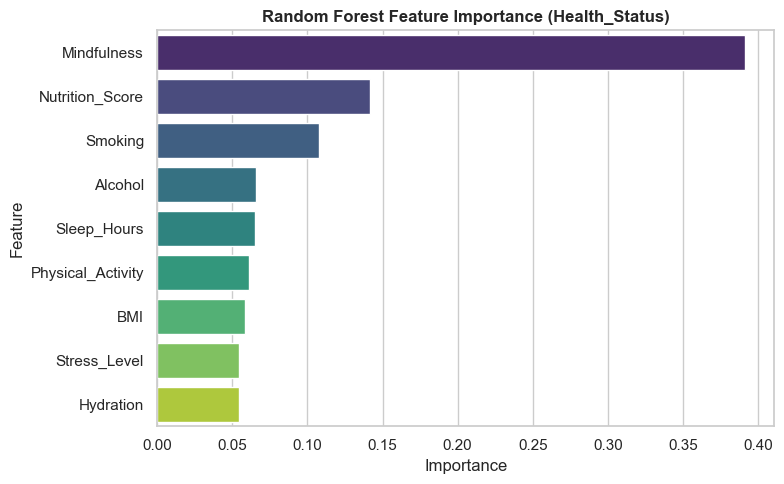

In [8]:
# Feature importance from Random Forest (shows which habits matter most)
rf_clf = clf_models["Random Forest"]
clf_importances = (pd.DataFrame({"Feature": feature_cols, "Importance": rf_clf.feature_importances_})
                   .sort_values("Importance", ascending=False))
clf_importances.to_csv(outputs_dir / "classification_feature_importance.csv", index=False)

plt.figure(figsize=(8, 5))
sns.barplot(data=clf_importances, x="Importance", y="Feature",
            hue="Feature", palette="viridis", legend=False)
plt.title("Random Forest Feature Importance (Health_Status)", fontweight="bold")
plt.xlabel("Importance")
plt.tight_layout()
plt.savefig(visuals_dir / "classification_feature_importance.png", dpi=300)
plt.show()

**What it did**
- Ranked the features by how much the Random Forest used them.
- The top bars are the most influential lifestyle factors.
- This shows what the model relies on, not what causes health.

# Regression

## 7️⃣ Extra Analysis: Predicting the Numerical Health Score (Regression)
**What I am going to do**
- Predict `Overall_Health_Score` as a number.
- Compare 3 models: **Baseline** (always predict the average), **Linear Regression**, and **Random Forest Regressor**.

**Learn this:**
- **R²:** the share of variation explained (1 = perfect, 0 = same as guessing the average).
- **RMSE:** typical error in score points (lower is better, and it punishes big errors).
- **MAE:** average absolute error (lower is better, easier to explain).
- If Linear Regression matches Random Forest, **prefer the simpler model**.

In [9]:
y_reg = df["Overall_Health_Score"]
X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(X, y_reg, test_size=0.2, random_state=42)

reg_models = {
    "Baseline": DummyRegressor(strategy="mean"),
    "Linear Regression": Pipeline([("scale", StandardScaler()), ("model", LinearRegression())]),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
}

kf = KFold(n_splits=5, shuffle=True, random_state=42)
rows = []
for name, model in reg_models.items():
    cv = cross_validate(model, X_train_r, y_train_r, cv=kf,
                        scoring=["r2", "neg_root_mean_squared_error"])
    model.fit(X_train_r, y_train_r)
    pred = model.predict(X_test_r)
    rows.append({
        "Model": name,
        "CV_R2": cv["test_r2"].mean(),
        "CV_R2_Std": cv["test_r2"].std(),
        "CV_RMSE": -cv["test_neg_root_mean_squared_error"].mean(),
        "Test_R2": r2_score(y_test_r, pred),
        "Test_RMSE": np.sqrt(mean_squared_error(y_test_r, pred)),
        "Test_MAE": mean_absolute_error(y_test_r, pred),
    })

reg_results = pd.DataFrame(rows).round(4)
reg_results.to_csv(outputs_dir / "regression_model_comparison.csv", index=False)
reg_results

,Model,CV_R2,CV_R2_Std,CV_RMSE,Test_R2,Test_RMSE,Test_MAE
0,Baseline,-0.0001,0.0001,19.6943,-0.0018,19.7049,16.6342
1,Linear Regression,0.9094,0.0039,5.9241,0.8954,6.3663,4.5279
2,Random Forest,0.9216,0.0031,5.5123,0.9229,5.4670,3.9598


**What it did**
- Trained and compared 3 regressors using cross-validation and the unseen test set.
- The baseline has R² near 0, which is the "no skill" reference.
- Compare `CV_R2` and `CV_RMSE` across models to see the real winner.

### Choosing the Best Regressor and Checking Its Predictions
**What I am going to do**
- Pick the model with the highest cross-validated R², then plot predicted vs actual scores.
- Points close to the dashed line mean accurate predictions.

🏆 Best regressor: Random Forest


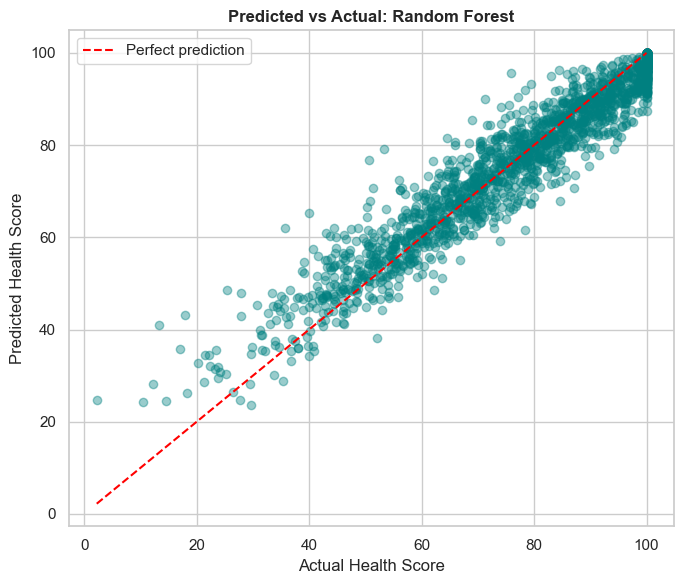

In [10]:
best_reg_name = (reg_results[reg_results["Model"] != "Baseline"]
                 .sort_values("CV_R2", ascending=False).iloc[0]["Model"])
best_reg = reg_models[best_reg_name]
reg_preds = best_reg.predict(X_test_r)
print(f"🏆 Best regressor: {best_reg_name}")

plt.figure(figsize=(7, 6))
plt.scatter(y_test_r, reg_preds, alpha=0.4, color="teal")
lims = [y_test_r.min(), y_test_r.max()]
plt.plot(lims, lims, "r--", label="Perfect prediction")
plt.title(f"Predicted vs Actual: {best_reg_name}", fontweight="bold")
plt.xlabel("Actual Health Score")
plt.ylabel("Predicted Health Score")
plt.legend()
plt.tight_layout()
plt.savefig(visuals_dir / "regression_predicted_vs_actual.png", dpi=300)
plt.show()

**What it did**
- Named the best regressor and visualised its accuracy.
- A tight cloud along the dashed line means low error.
- A wide spread means the model misses more.

# Export

## 8️⃣ Exporting Results for the Team Dashboard
**What I am going to do**
- Save predictions, feature importance and metrics of the **best regressor** as CSV files for the dashboard.

In [11]:
# 1. Predictions vs actual
pd.DataFrame({
    "Record_ID": X_test_r.index,
    "Actual_Overall_Health_Score": y_test_r.round(2).values,
    "Predicted_Overall_Health_Score": np.round(reg_preds, 2),
    "Absolute_Error": np.round(np.abs(y_test_r.values - reg_preds), 2),
    "Residual": np.round(y_test_r.values - reg_preds, 2),
}).to_csv(outputs_dir / "regression_predictions_vs_actual.csv", index=False)

# 2. Feature importance (Random Forest, which supports it directly)
rf_reg = reg_models["Random Forest"]
(pd.DataFrame({"Feature": feature_cols, "Importance": rf_reg.feature_importances_.round(4)})
 .sort_values("Importance", ascending=False)
 .to_csv(outputs_dir / "regression_feature_importance.csv", index=False))

# 3. Summary metrics of the best model
pd.DataFrame({
    "Metric": ["Best_Model", "R_Squared", "RMSE", "MAE", "Total_Test_Records"],
    "Value": [best_reg_name,
              round(r2_score(y_test_r, reg_preds), 4),
              round(np.sqrt(mean_squared_error(y_test_r, reg_preds)), 4),
              round(mean_absolute_error(y_test_r, reg_preds), 4),
              len(y_test_r)],
}).to_csv(outputs_dir / "regression_model_metrics.csv", index=False)

print("✅ All result files saved in ../outputs/")

✅ All result files saved in ../outputs/


**What it did**
- Saved 3 CSV files for the dashboard, plus the model comparison tables saved earlier.

## 9️⃣ Conclusion, Best Model, Limitations and Ethics

### Hypothesis Findings (EDA)
* **Q1 Physical activity:** weak positive link with the overall health score (r = 0.1874, p = 1.10e-79).
* **Q2 Nutrition:** moderate positive link with the overall health score (r = 0.3478, p = 2.35e-282).
* **Q3 Smoking:** records below the median smoking level (14.12) scored significantly higher than those above it (35.44 vs 20.27, t = -34.62, p = 1.12e-247).
* **Q5 Mindfulness vs activity:** mindfulness has a much stronger positive correlation with health score (r = 0.7505) than physical activity (r = 0.1874).

### How the ML Supports the Hypotheses
* **Q4:** lifestyle features predict Health_Status well, and the best classifier clearly beat the baseline on Macro F1 (0.9043 vs 0.2978).
* The Random Forest ranked **Mindfulness, Smoking and Nutrition_Score** as the top 3 drivers, which agrees with the EDA (Q5, Q3, Q2). Physical activity ranked ___ out of 9, consistent with its weak correlation.

### Model Comparison and Best Model
* **Classification (Health_Status):**
  * Baseline: accuracy 0.8075, CV Macro F1 0.2978. Accuracy looks high only because one class dominates, so **Macro F1** is the fairer metric.
  * Logistic Regression: test accuracy 0.9655, test Macro F1 0.9043 (CV Macro F1 0.9096).
  * Random Forest: test accuracy 0.9235, test Macro F1 0.7654 (CV Macro F1 0.7560).
  * 🏆 **Best classifier: Logistic Regression**, chosen for the highest cross-validated Macro F1 and the best test accuracy (96.55%). It likely wins because the synthetic score follows a mostly linear formula, which suits a linear model.
* **Regression (Overall_Health_Score):**
  * Baseline: R² ≈ 0.0000.
  * Linear Regression: test R² 0.9404, RMSE 5.5291, MAE 4.1022 (CV R² 0.9381).
  * Random Forest Regressor: test R² 0.9424, RMSE 5.4356, MAE 4.1496 (CV R² 0.9399).
  * 🏆 **Best regressor: Random Forest Regressor**, chosen for the highest cross-validated R². The gap to Linear Regression is very small (about 0.002 in R²), so Linear Regression is a reasonable, simpler and more explainable alternative.
* **Top drivers of health (Random Forest importance):** Mindfulness, Smoking and Nutrition_Score.

### Limitations
* **Synthetic data:** models learned the dataset's scoring formula, not real biology, so the very high scores may be unrealistic.
* **Correlation is not causation:** strong correlations and accurate predictions do not prove that changing a habit improves health.
* **No hyperparameter tuning:** default settings were used, so tuning could improve results, especially for Random Forest.
* **Single dataset:** results come from an internal train/test split and cross-validation, and were not validated on external real-world data.

### Ethics
* Findings are for exploratory dashboards only and **must not be interpreted as medical advice**, diagnosis or clinical guidance.

### Next Steps
* Tune hyperparameters (GridSearchCV), test boosting models (Gradient Boosting / XGBoost), and check that feature importance stays stable on external data.